# Settings

In [1]:
from pathlib import Path
import os

repo_root = Path("/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDLEAD")
os.chdir(repo_root)

In [2]:
import json
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import mne

mne.set_log_level("WARNING")

STUDIES = {
    "Study 1": dict(root=repo_root / Path("Study1/epochs/hp0.1_lp40"), pattern="*-epo.fif",
                    group_from="filename_suffix", group_order=["Passive", "Active"], split_col=None,
                    roi=["Fz", "FCz", "Cz"], montage=None),
    "Study 2": dict(root=repo_root / Path("Study2/epochs/hp0.1_lp40"), pattern="*-epo.fif",
                            group_from="filename", group_order=["adults", "11MO", "4MO"], split_col=None,
                            roi=["Fz", "Cz"], montage=None),
    "Study 3": dict(root=repo_root / Path("Study3/epochs/hp0.1_lp40"), pattern="*-epo.fif",
                        group_from="json", group_order=["CS", "MCS", "VS"], split_col="task_relevant",
                        roi=None, montage=None),
}

JSON_NAMES = ["{sub}.json", "{sub}_info.json", "{sub}-info.json", "{sub}_qc.json"]
COND_COL = "snr"
REST_LABEL = 0
BASELINE = (-0.2, 0.0)
TOPO_TIMES = [0.1, 0.2, 0.3, 0.45, 0.6, 0.8]
TOPO_AVG = 0.05

# Functions

In [3]:
def read_group(f, how):
    sub = f.name.replace("-epo.fif", "")
    if how is None:
        return "all"
    if how == "filename":
        return sub.split("_")[0]
    if how == "filename_suffix":
        return sub.split("_")[-1]
    for name in JSON_NAMES:
        p = f.parent / name.format(sub=sub)
        if p.exists():
            return str(json.loads(p.read_text())["group"])
    raise FileNotFoundError(f"No json for {sub} (tried {JSON_NAMES} in {f.parent})")


def load_study(cfg):
    files = sorted(cfg["root"].glob(cfg["pattern"]))
    if not files:
        raise FileNotFoundError(f"No files matching {cfg['pattern']} in {cfg['root']}")
    out = {}
    for f in files:
        ep = mne.read_epochs(f, preload=True)
        if cfg["montage"] is not None:
            ep.set_montage(cfg["montage"], on_missing="warn")
        if cfg["split_col"] and cfg["split_col"] not in ep.metadata:
            raise KeyError(f"{f.name}: no '{cfg['split_col']}' column, has {list(ep.metadata.columns)}")
        out[f.name.replace("-epo.fif", "")] = (ep, read_group(f, cfg["group_from"]))
    return out


def subject_evokeds(ep, baseline=BASELINE):
    evs = {}
    for c in sorted(ep.metadata[COND_COL].unique()):
        sub = ep[(ep.metadata[COND_COL] == c).to_numpy()]
        if len(sub):
            ev = sub.average()
            if baseline is not None:
                ev.apply_baseline(baseline)
            ev.comment = "rest" if c == REST_LABEL else f"{COND_COL}={c}"
            evs[ev.comment] = ev
    return evs


def split_epochs(ep, split_col):
    if split_col is None:
        return {"": ep}
    md = ep.metadata
    is_rest = md[COND_COL] == REST_LABEL
    return {str(v): ep[(is_rest | (md[split_col] == v)).to_numpy()]
            for v in md.loc[~is_rest, split_col].unique()}


def collect_evokeds(subjects, cfg):
    cells = defaultdict(lambda: defaultdict(list))
    for ep, group in subjects.values():
        for split, sub_ep in split_epochs(ep, cfg["split_col"]).items():
            for cond, ev in subject_evokeds(sub_ep).items():
                cells[(group, split, len(ep.ch_names))][cond].append(ev)
    order = cfg["group_order"] or []
    rank = lambda k: (order.index(k[0]) if k[0] in order else len(order), k[0], k[1], k[2])
    return {k: dict(cells[k]) for k in sorted(cells, key=rank)}


def cond_order(conds):
    return sorted(conds, key=lambda c: (c != "rest", float(c.split("=")[-1]) if "=" in c else -1))


def cell_title(study, key, cells):
    group, split, n_ch = key
    parts = [study] + ([group] if group != "all" else []) + ([split.upper()] if split else [])
    several_nets = len({k[2] for k in cells}) > 1
    return " – ".join(parts) + (f" ({n_ch} ch)" if several_nets else "")


def plot_erps(study, cells, roi):
    for key, conds in cells.items():
        conds = {c: conds[c] for c in cond_order(conds)}
        n_sub = max(len(v) for v in conds.values())
        ch = conds[next(iter(conds))][0].ch_names
        picks = [c for c in roi if c in ch] if roi else "eeg"
        combine = "mean" if roi else "gfp"
        if roi and not picks:
            picks, combine = "eeg", "gfp"
        cols = plt.get_cmap("viridis")(np.linspace(0, 0.85, len(conds)))
        colors = {c: ("0.5" if c == "rest" else tuple(cols[i])) for i, c in enumerate(conds)}
        fig, ax = plt.subplots(figsize=(8, 4))
        mne.viz.plot_compare_evokeds(conds, picks=picks, combine=combine, colors=colors,
                                     ci=0.95, axes=ax, show=False,
                                     title=f"{cell_title(study, key, cells)}, n={n_sub} " +
                                           (f"| ROI {','.join(picks)}" if combine == "mean" else ""))
        plt.show()


def plot_topo_grid(study, cells, times=TOPO_TIMES, avg=TOPO_AVG):
    for key, conds in cells.items():
        names = cond_order(conds)
        gavg = {c: mne.grand_average(conds[c]) for c in names}
        info = gavg[names[0]].info
        maps = {c: np.stack([gavg[c].copy().crop(t - avg / 2, t + avg / 2)
                             .data.mean(axis=1) for t in times], axis=1) * 1e6
                for c in names}
        vmax = np.percentile(np.abs(np.concatenate(list(maps.values()))), 99)
        fig, axes = plt.subplots(len(names), len(times),
                                 figsize=(1.6 * len(times) + 1, 1.6 * len(names)),
                                 squeeze=False, layout="constrained")
        for i, c in enumerate(names):
            for j, t in enumerate(times):
                im, _ = mne.viz.plot_topomap(maps[c][:, j], info, axes=axes[i, j], show=False,
                                             vlim=(-vmax, vmax), cmap="RdBu_r", contours=0)
                if i == 0:
                    axes[i, j].set_title(f"{int(t * 1000)} ms")
            axes[i, 0].set_ylabel(c, rotation=0, ha="right", va="center")
            axes[i, 0].yaxis.set_visible(True)
            axes[i, 0].set_yticks([])
        fig.colorbar(im, ax=axes, shrink=0.6, label="µV")
        fig.suptitle(f"{cell_title(study, key, cells)} – grand average")
        plt.show()

# Load the epochs

In [4]:
data = {name: load_study(cfg) for name, cfg in STUDIES.items()}
cells = {name: collect_evokeds(data[name], STUDIES[name]) for name in STUDIES}

for name, c in cells.items():
    for key, conds in c.items():
        print(name, key, {cond: len(v) for cond, v in conds.items()})

Study 1 ('Passive', '', 64) {'rest': 21, 'snr=1': 21, 'snr=2': 21, 'snr=3': 21, 'snr=4': 21, 'snr=5': 21, 'snr=6': 11}
Study 1 ('Active', '', 64) {'rest': 21, 'snr=1': 21, 'snr=2': 21, 'snr=3': 21, 'snr=4': 21, 'snr=5': 21}
Study 2 ('adults', '', 13) {'rest': 32, 'snr=1': 32, 'snr=2': 32, 'snr=3': 32, 'snr=4': 32, 'snr=5': 32}
Study 2 ('11MO', '', 13) {'rest': 41, 'snr=1': 41, 'snr=2': 41, 'snr=3': 41, 'snr=4': 41}
Study 2 ('4MO', '', 13) {'rest': 48, 'snr=1': 48, 'snr=2': 48, 'snr=3': 48, 'snr=4': 48}
Study 3 ('CS', 'False', 80) {'rest': 2, 'snr=1': 2, 'snr=2': 2, 'snr=3': 2, 'snr=4': 2, 'snr=5': 2}
Study 3 ('CS', 'False', 186) {'rest': 1, 'snr=1': 1, 'snr=2': 1, 'snr=3': 1, 'snr=4': 1, 'snr=5': 1}
Study 3 ('CS', 'True', 80) {'rest': 2, 'snr=5': 2}
Study 3 ('CS', 'True', 186) {'rest': 1, 'snr=5': 1}
Study 3 ('MCS', 'False', 80) {'rest': 3, 'snr=1': 3, 'snr=2': 3, 'snr=3': 3, 'snr=4': 3, 'snr=5': 3}
Study 3 ('MCS', 'False', 129) {'rest': 2, 'snr=1': 2, 'snr=2': 2, 'snr=3': 2, 'snr=4': 

# Plotting ERPs

/tmp/ipykernel_570646/1274890187.py:87: RuntimeWarning: Order of channels differs, reordering channels ...
  mne.viz.plot_compare_evokeds(conds, picks=picks, combine=combine, colors=colors,
/tmp/ipykernel_570646/1274890187.py:87: RuntimeWarning: Order of channels differs, reordering channels ...
  mne.viz.plot_compare_evokeds(conds, picks=picks, combine=combine, colors=colors,
/tmp/ipykernel_570646/1274890187.py:87: RuntimeWarning: Order of channels differs, reordering channels ...
  mne.viz.plot_compare_evokeds(conds, picks=picks, combine=combine, colors=colors,
/tmp/ipykernel_570646/1274890187.py:87: RuntimeWarning: Order of channels differs, reordering channels ...
  mne.viz.plot_compare_evokeds(conds, picks=picks, combine=combine, colors=colors,
/tmp/ipykernel_570646/1274890187.py:87: RuntimeWarning: Order of channels differs, reordering channels ...
  mne.viz.plot_compare_evokeds(conds, picks=picks, combine=combine, colors=colors,
/tmp/ipykernel_570646/1274890187.py:87: RuntimeWar

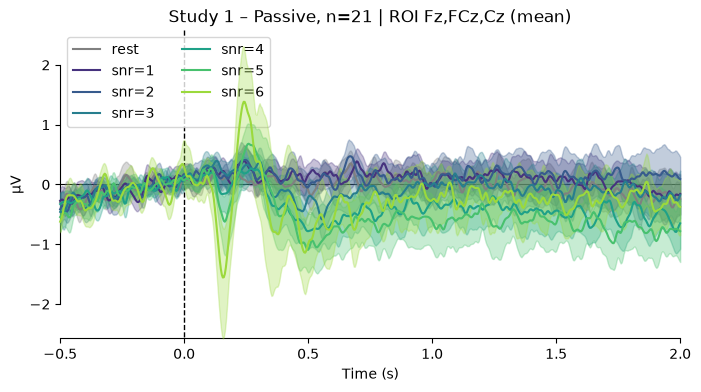

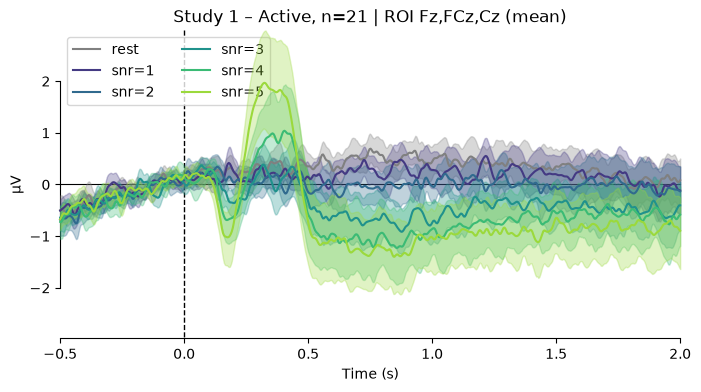

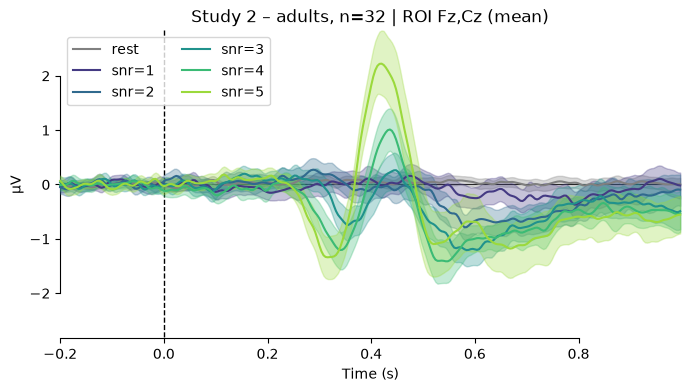

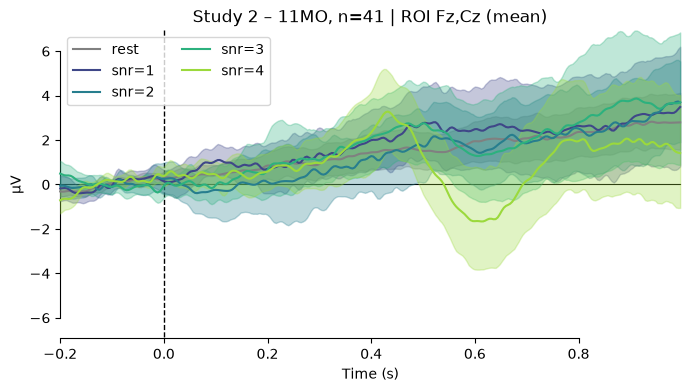

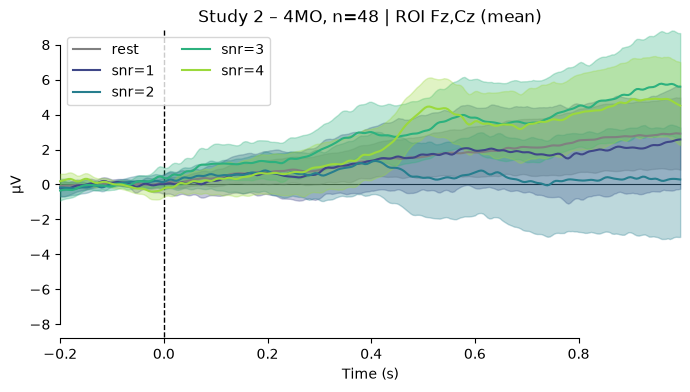

...

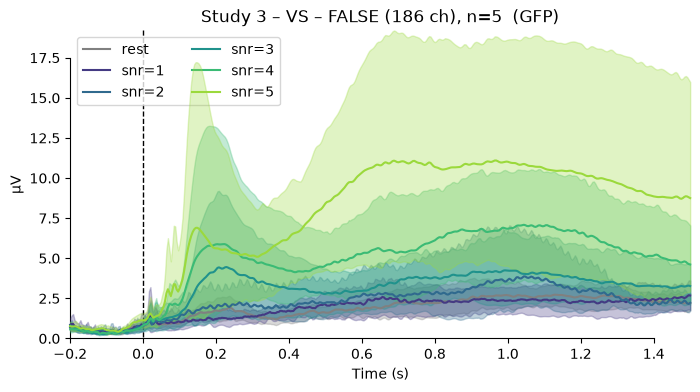

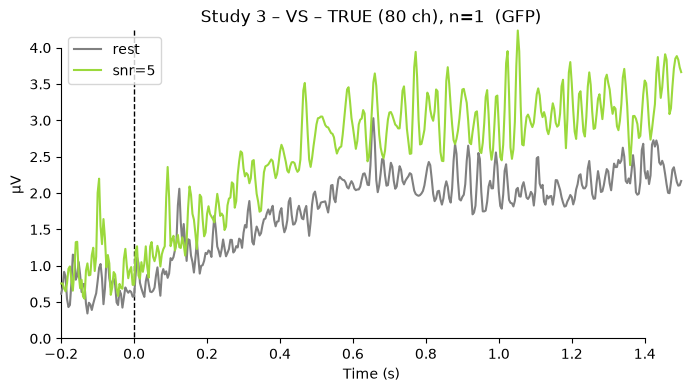

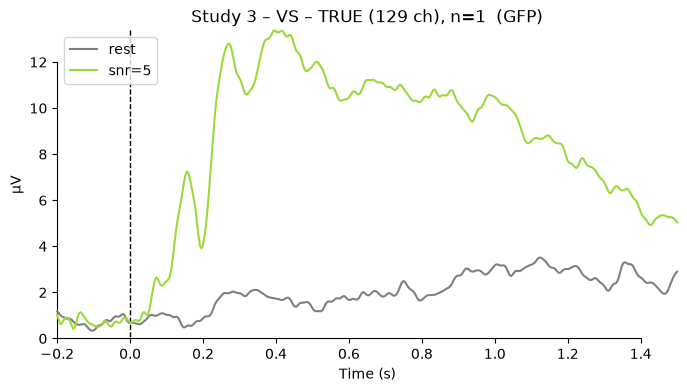

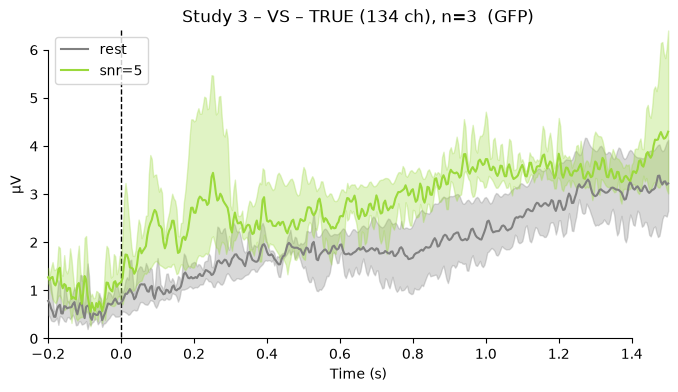

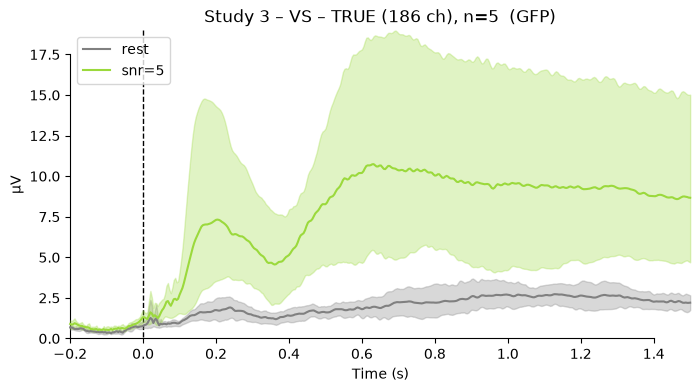

In [5]:
for name in STUDIES:
    plot_erps(name, cells[name], STUDIES[name]["roi"])

# Topographies

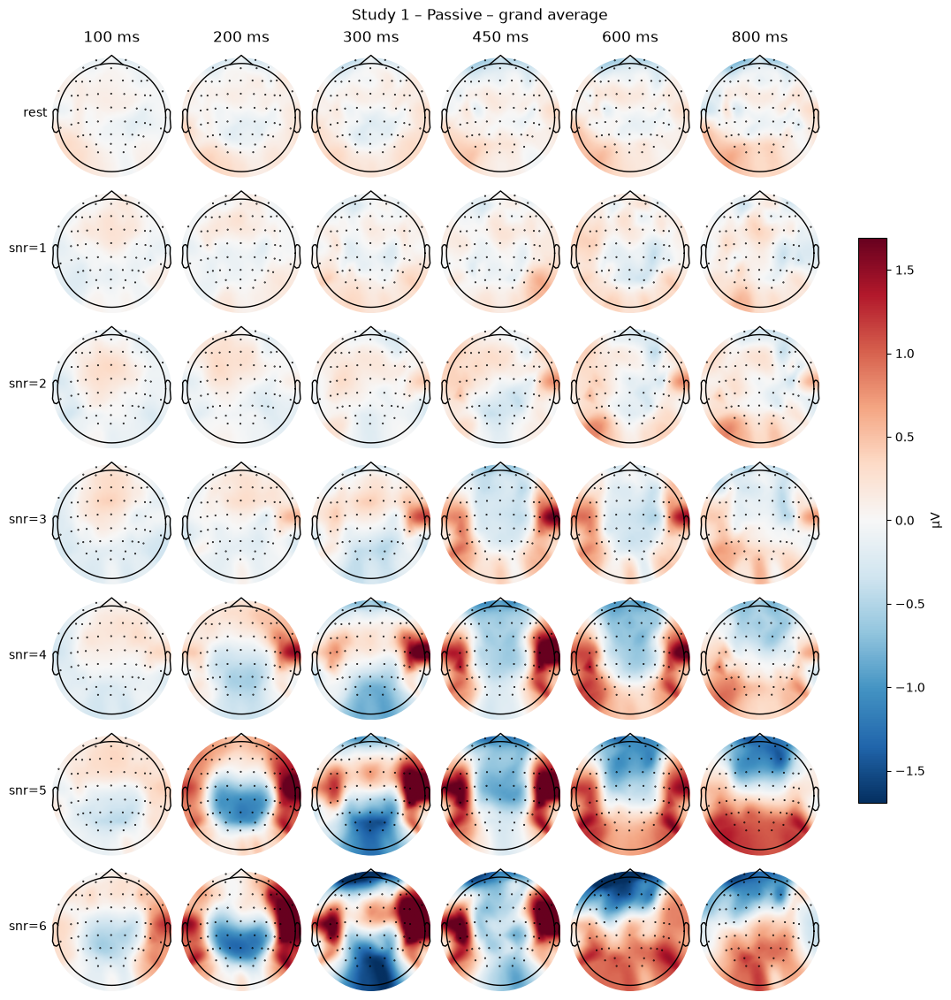

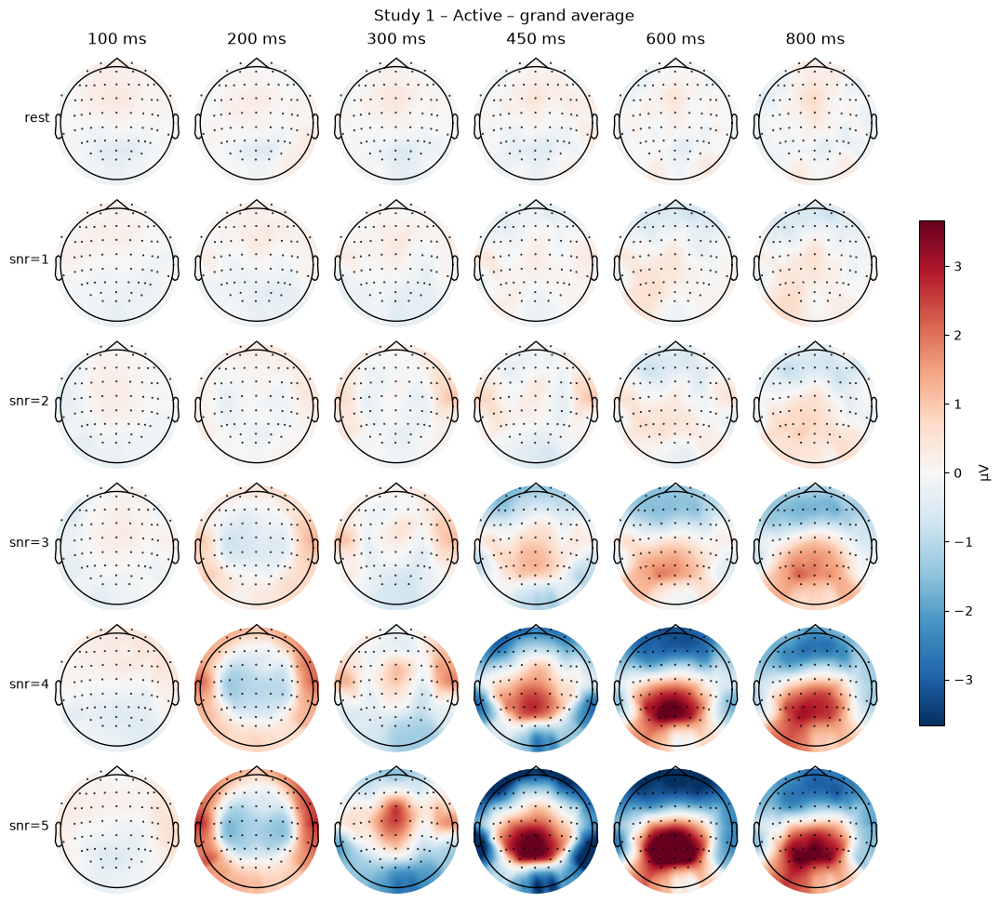

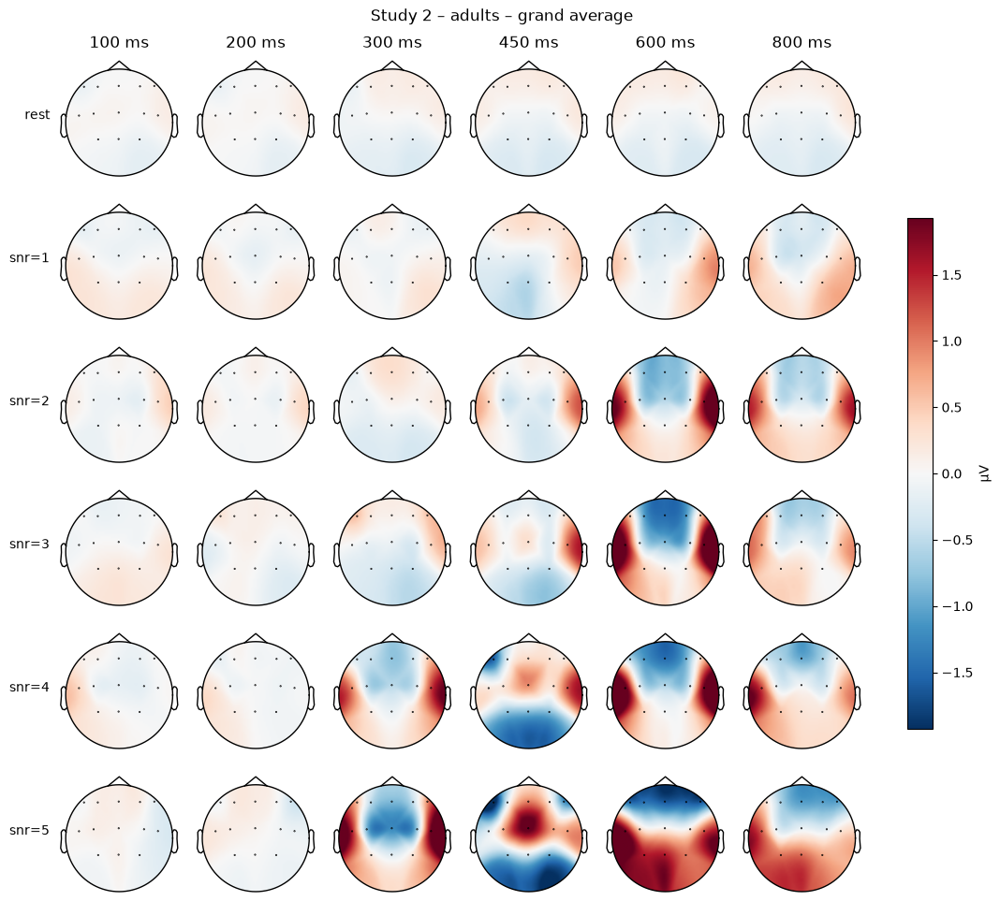

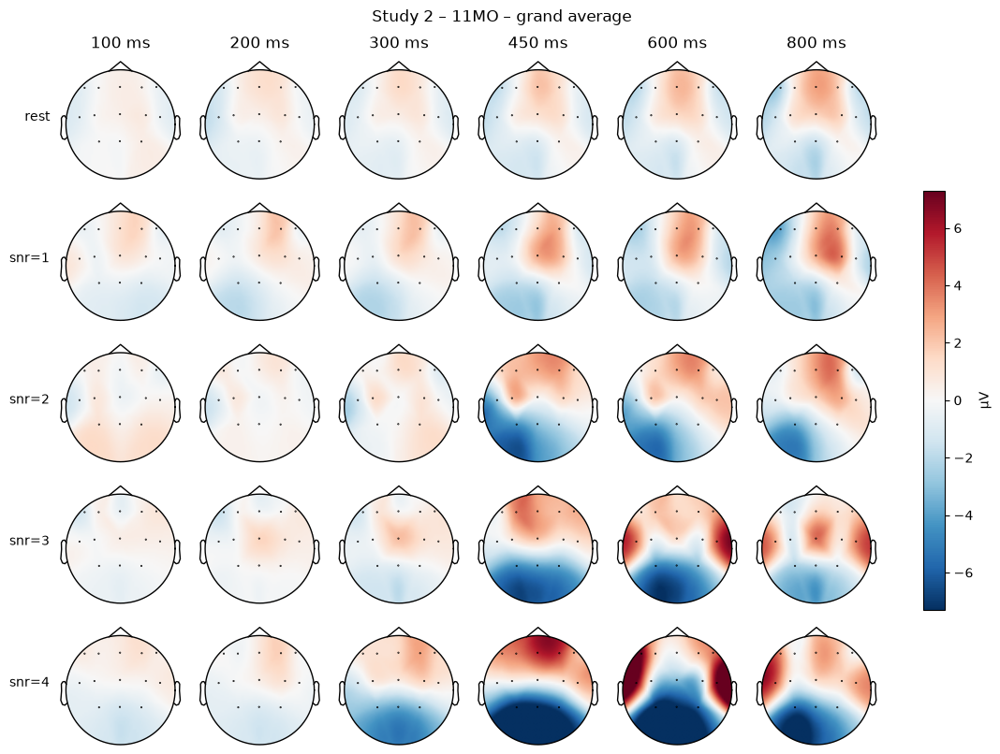

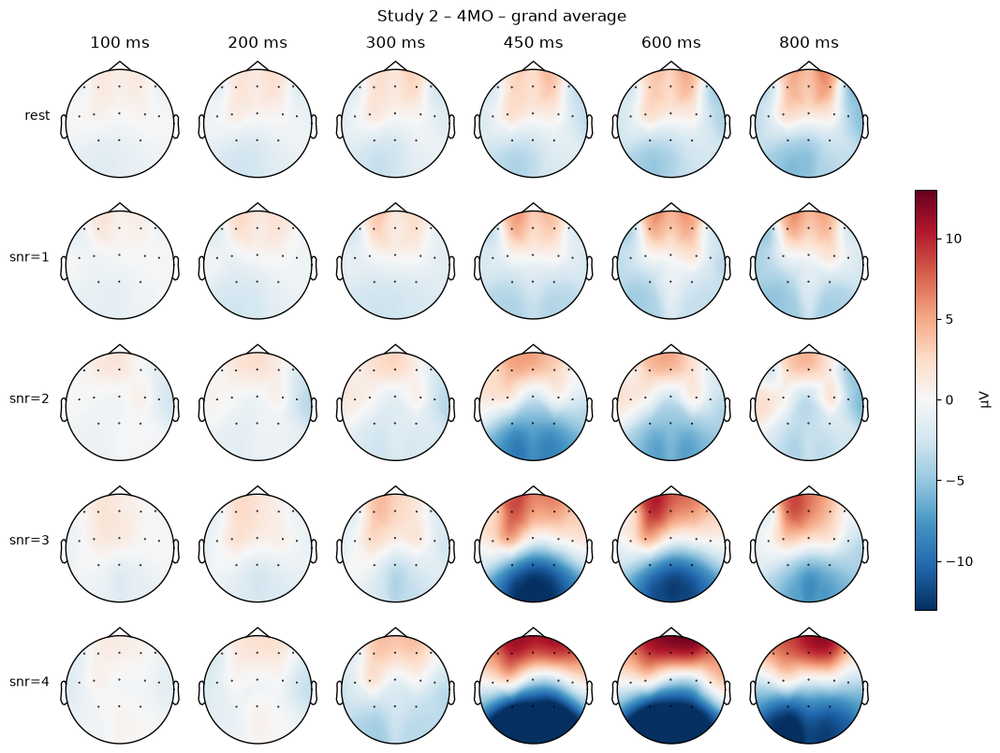

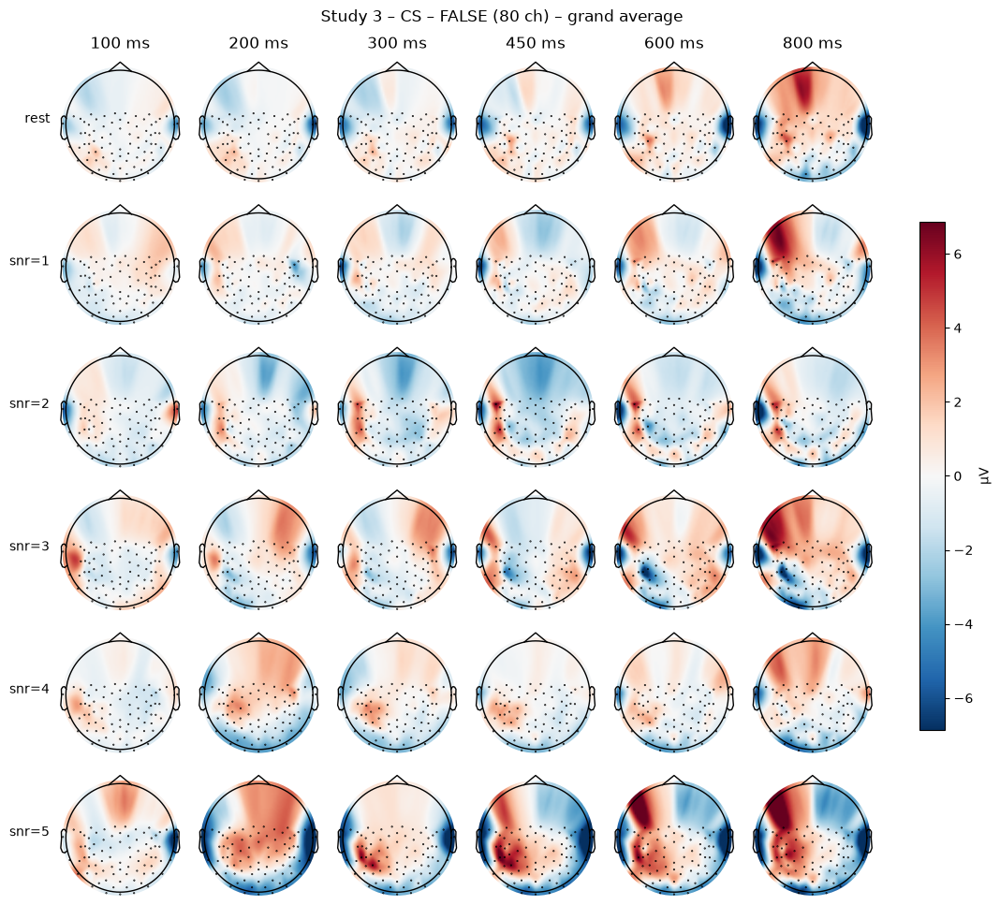

/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[

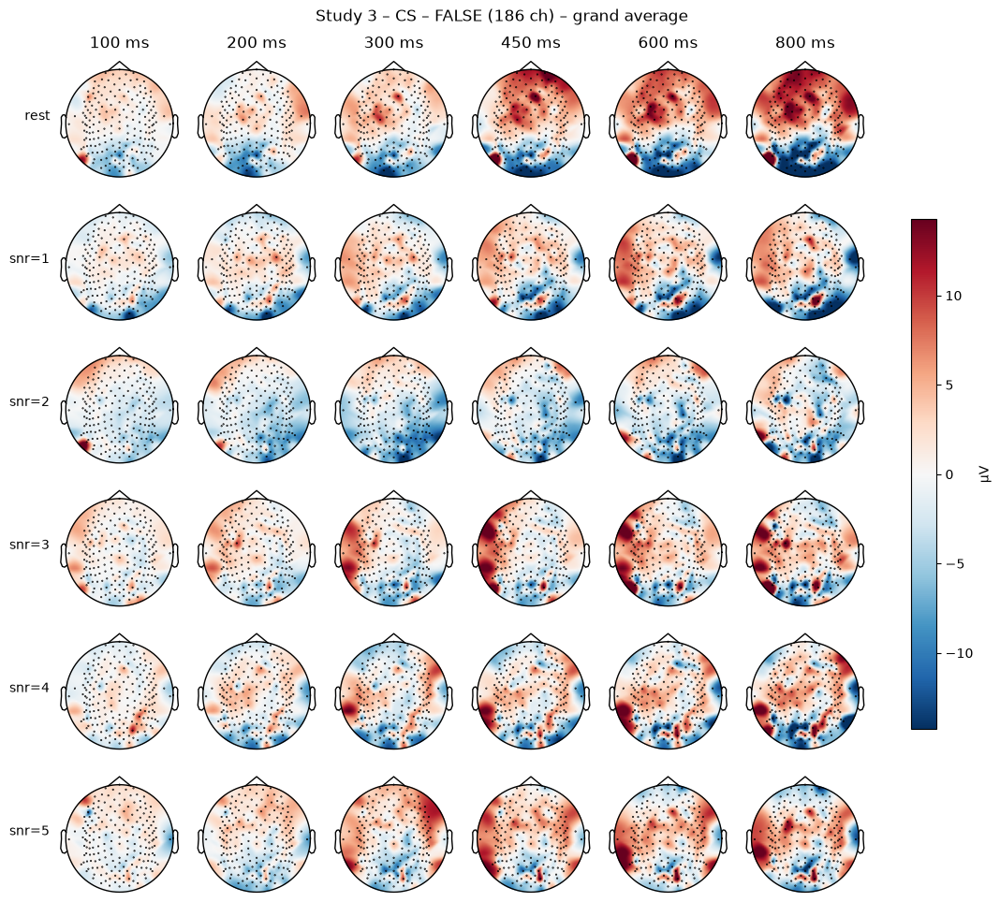

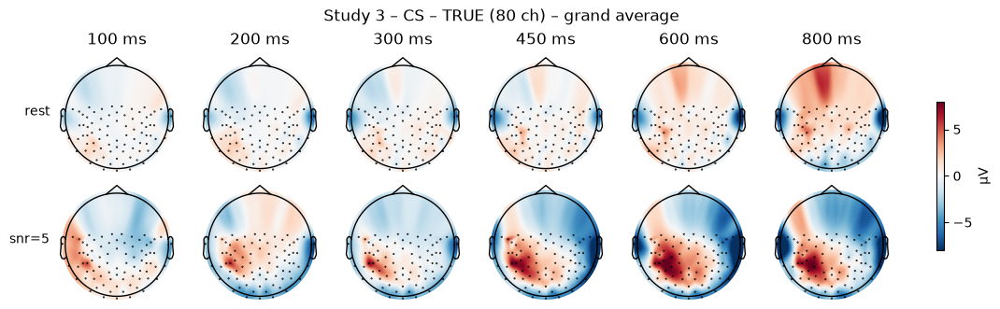

/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}


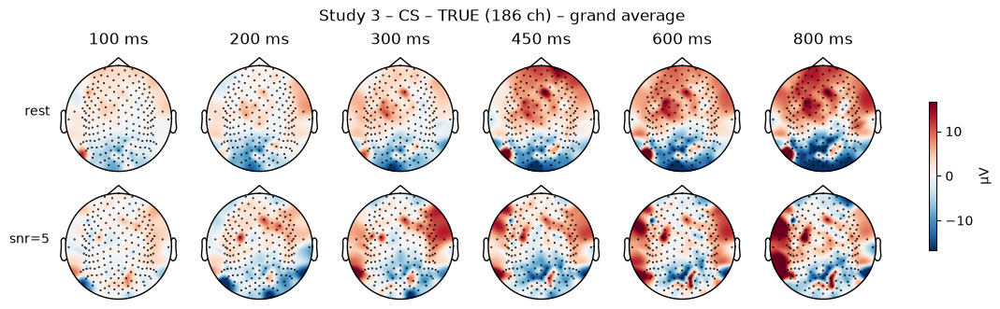

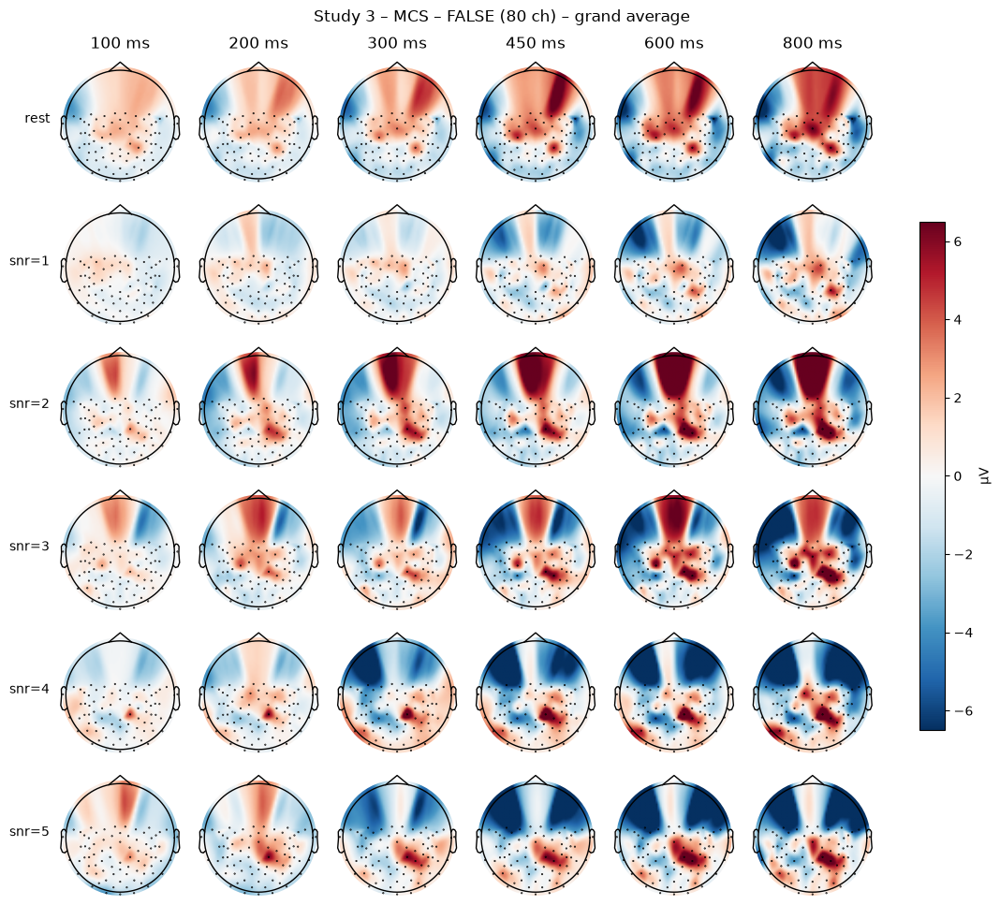

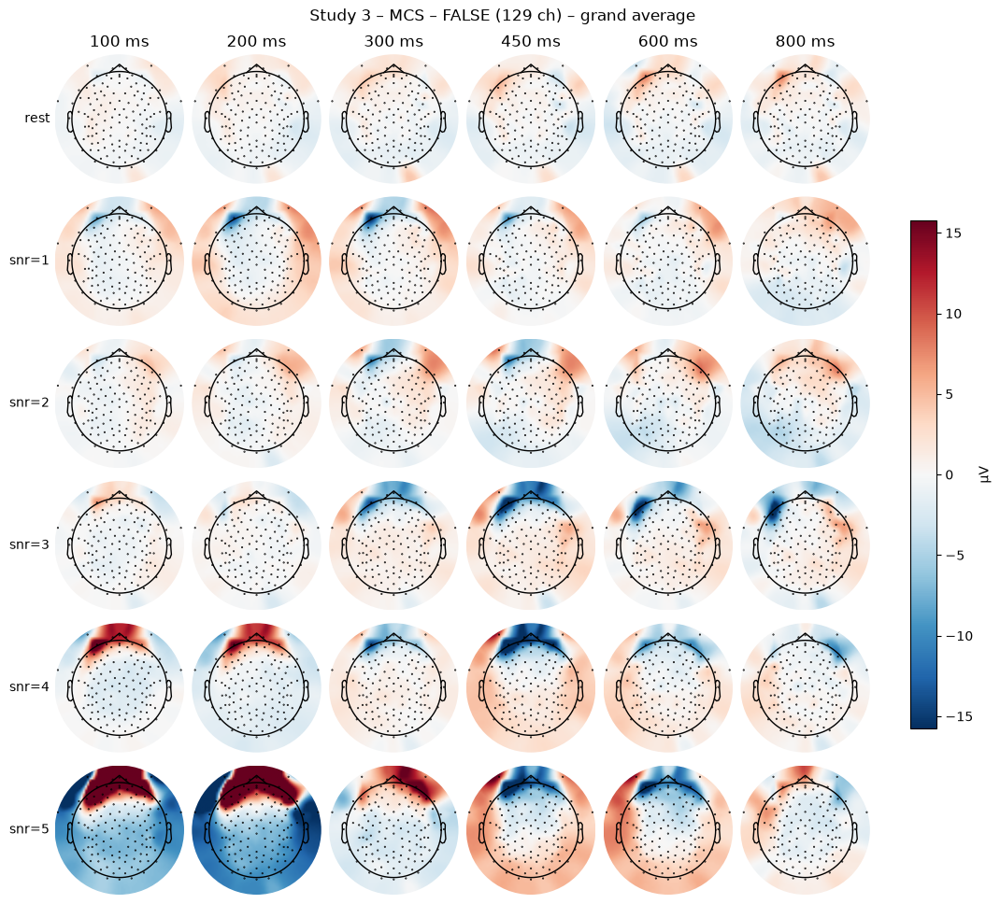

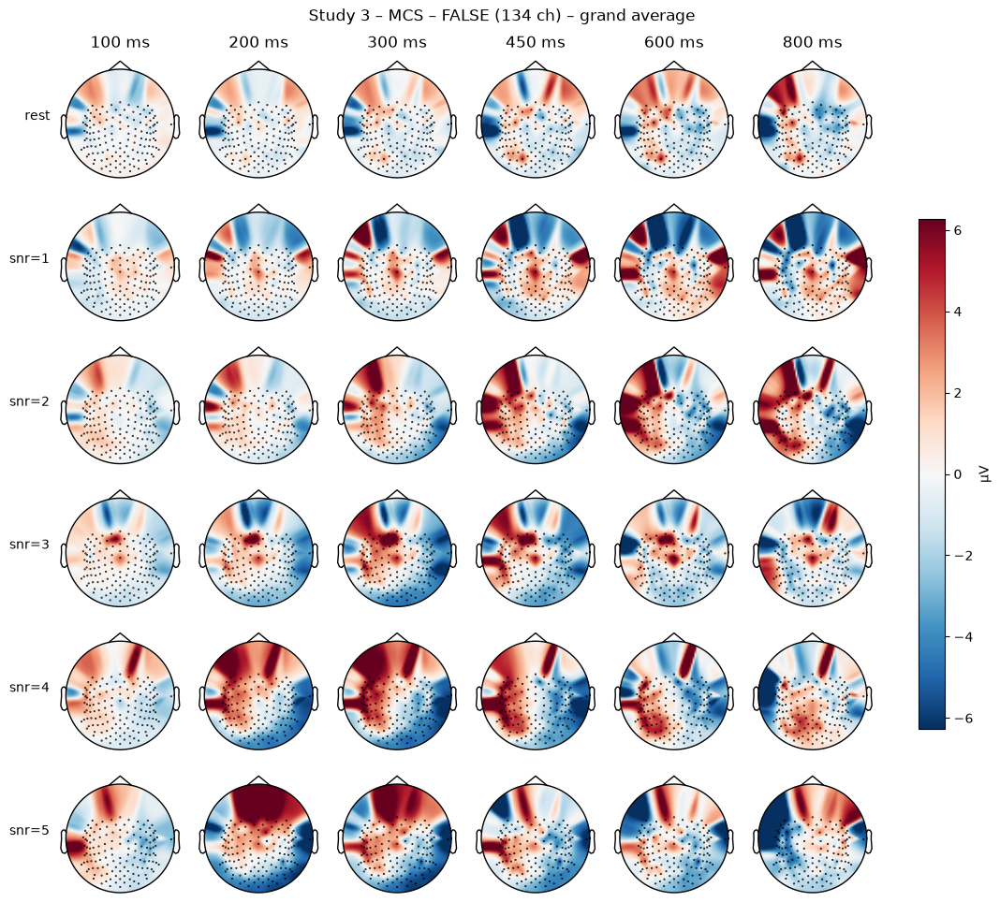

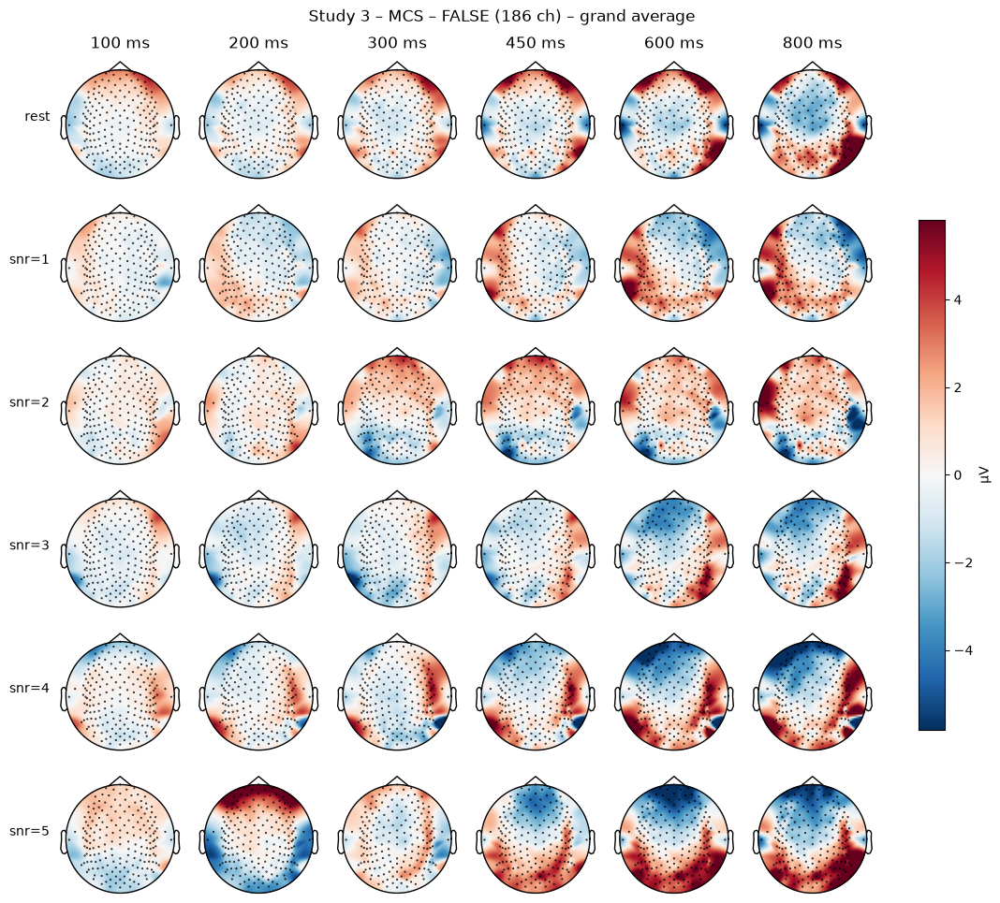

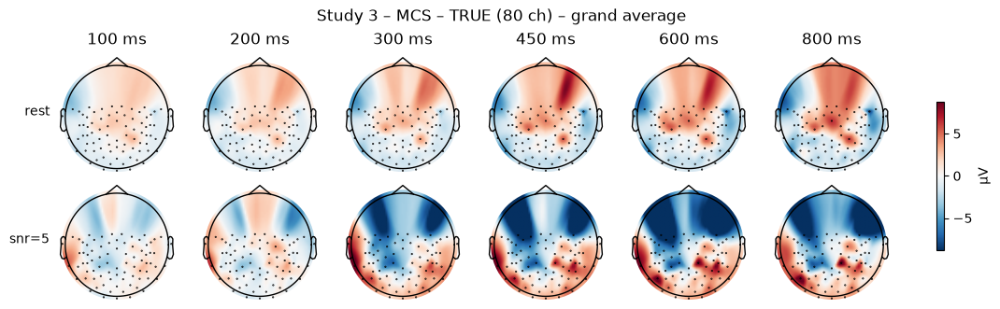

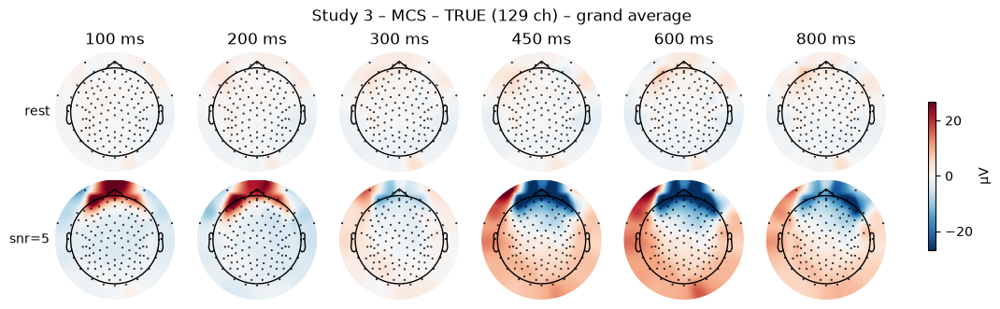

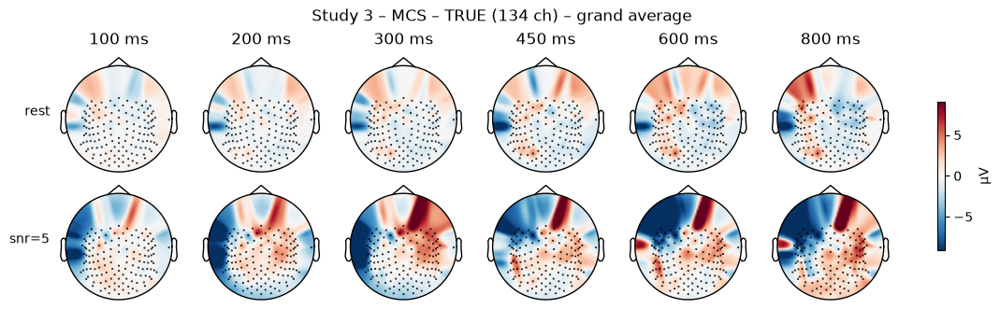

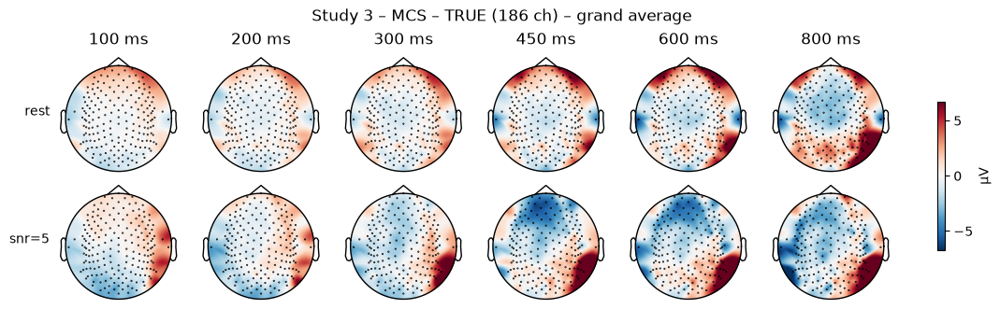

/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[

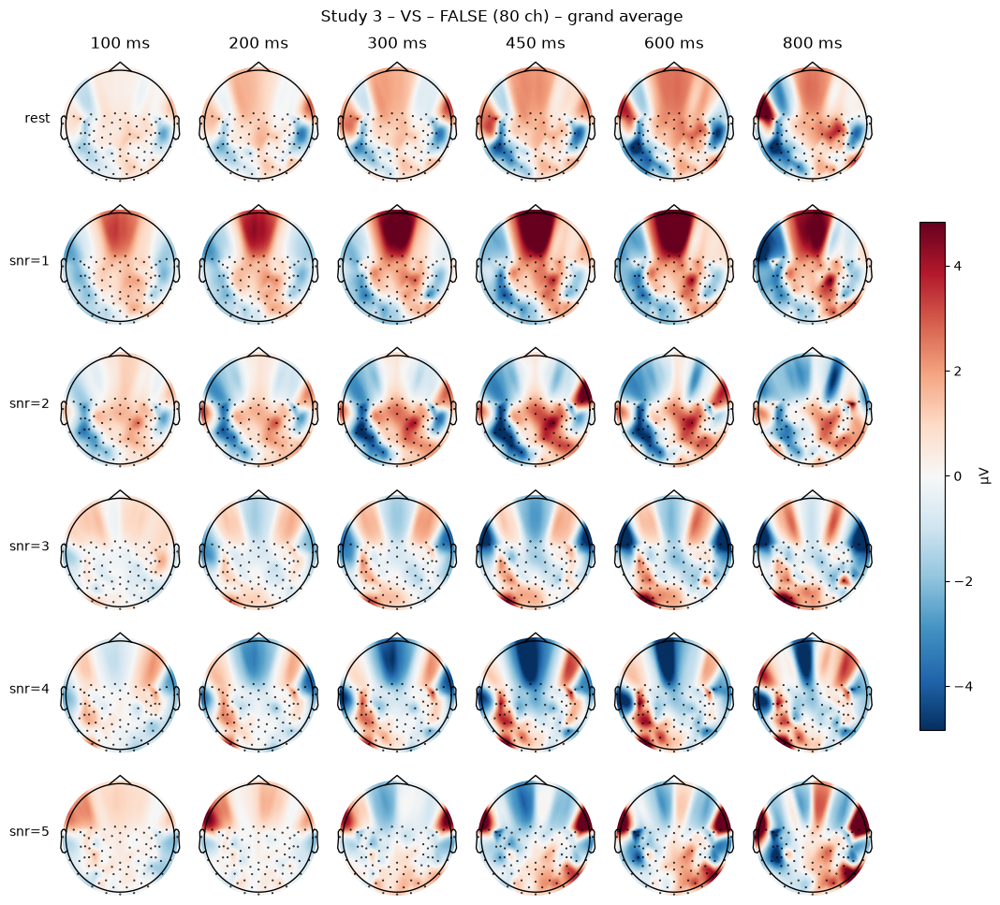

/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[

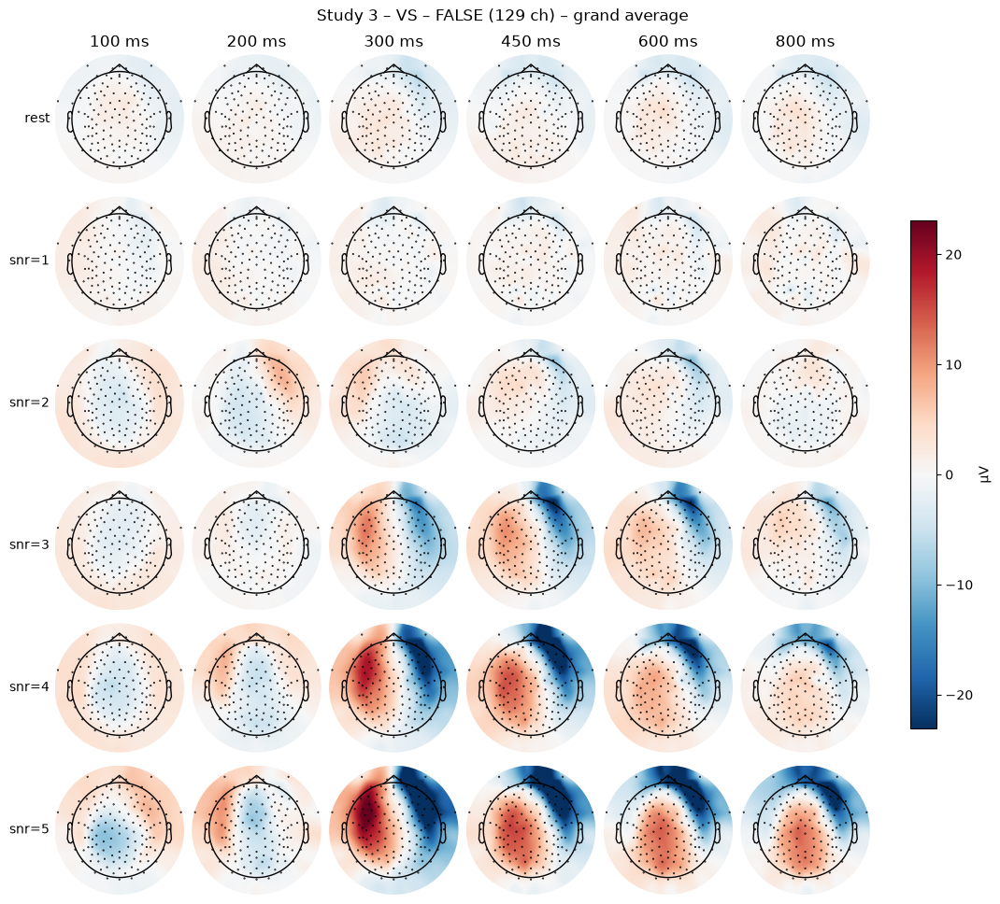

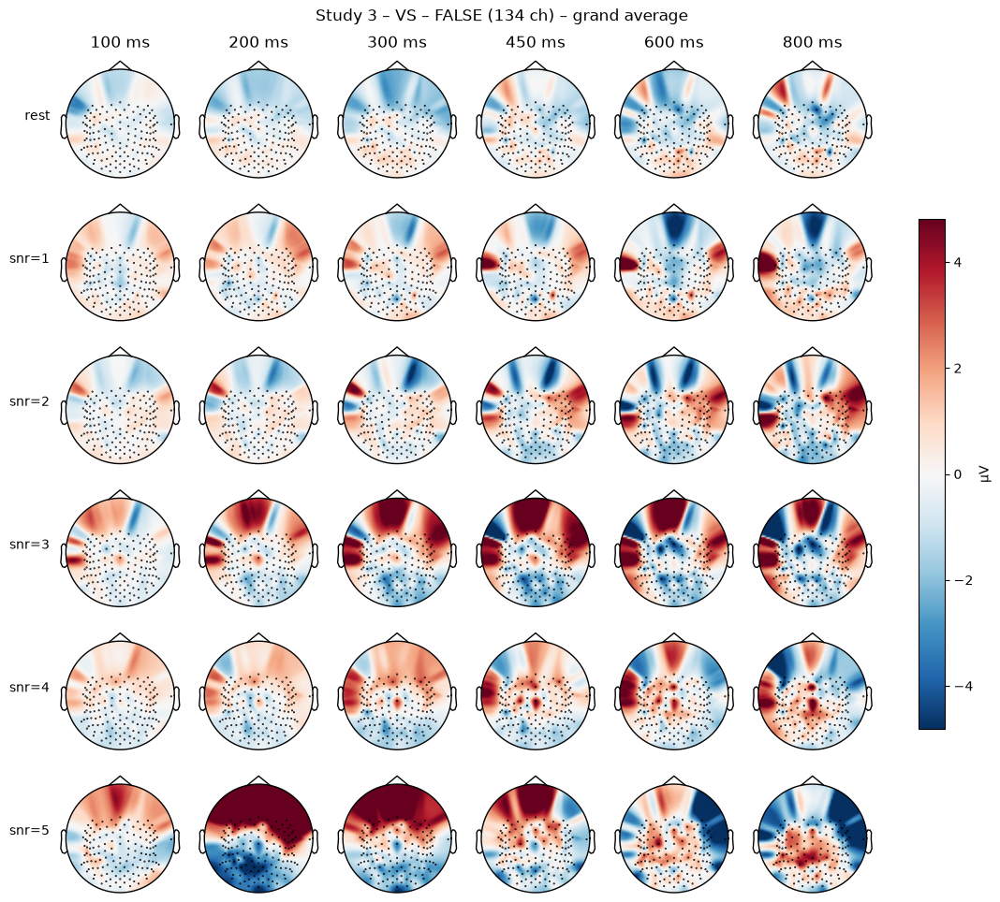

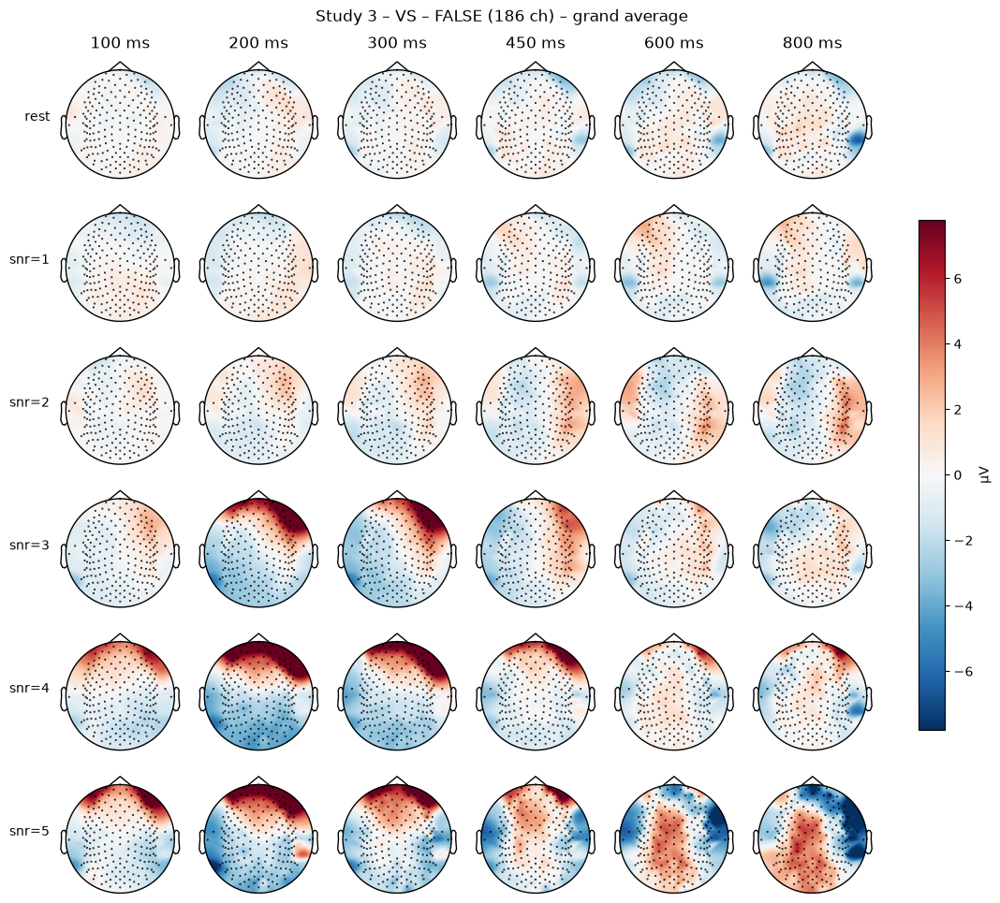

/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}


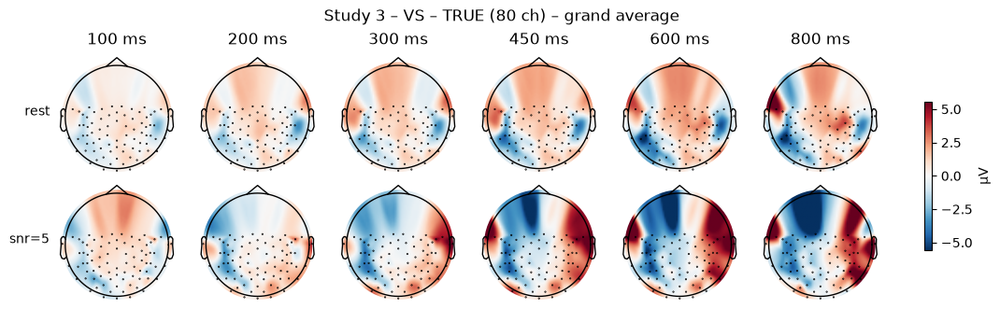

/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}
/tmp/ipykernel_570646/1274890187.py:97: RuntimeWarning: Only a single dataset was passed to mne.grand_average().
  gavg = {c: mne.grand_average(conds[c]) for c in names}


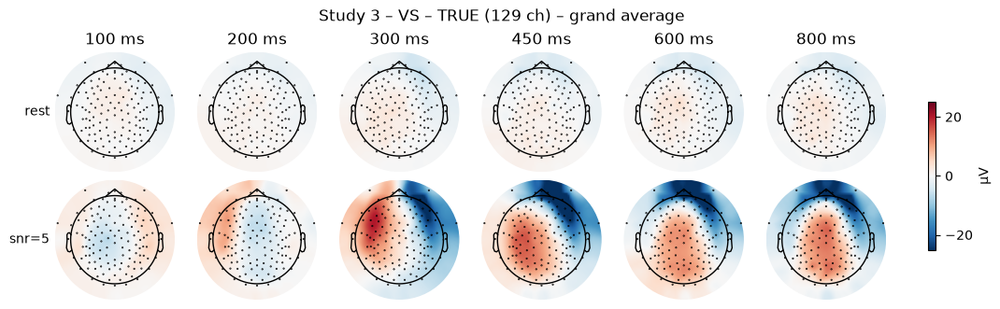

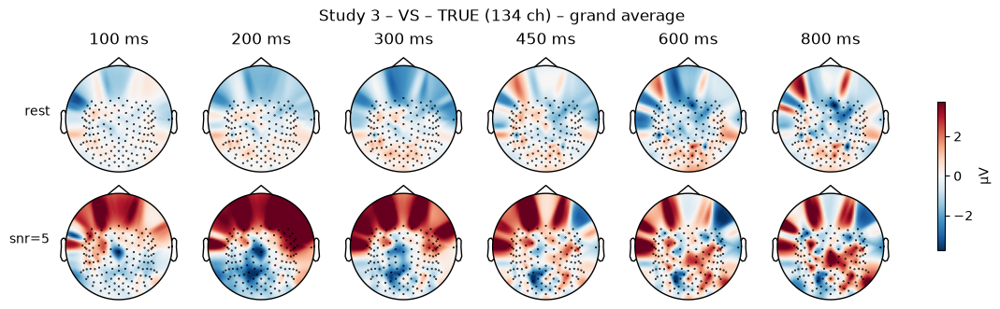

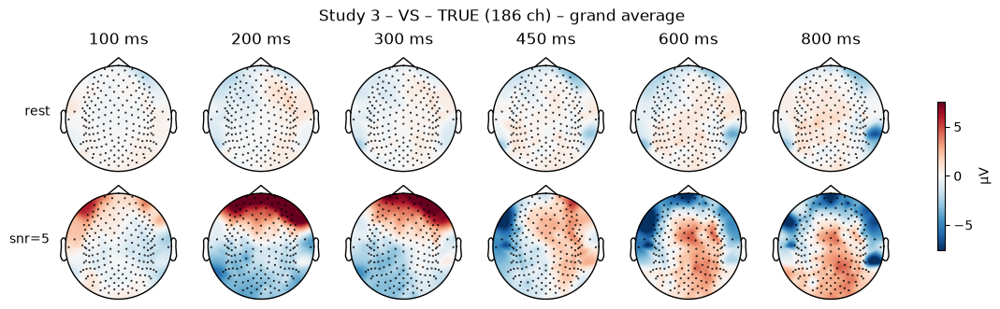

In [6]:
for name in STUDIES:
    plot_topo_grid(name, cells[name])